<a href="https://colab.research.google.com/github/Farouk41/Twitter_Sentiment_Analysis/blob/main/Twitter_Sentiment_Analysis_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Twitter Sentiment Analysis using Python

In [ ]:
import re, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import BernoulliNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---------------- Settings ----------------
DATA_PATH     = "training.1600000.processed.noemoticon.csv"
SAMPLE_SIZE   = 200_000   # balanced sample size (set to None to use all 1.6M tweets - very slow)
EMB_TWEETS    = 100_000   # number of training tweets used to train CBOW / Skip-gram
EMB_DIM       = 50        # embedding vector size
WINDOW        = 2         # context window size
VOCAB_SIZE    = 10_000    # max vocabulary size
MAX_LEN       = 30        # max tweet length (in words) for the deep learning models
EMB_EPOCHS    = 3         # epochs for training the embeddings
DL_EPOCHS     = 5         # epochs for the deep learning classifiers
SELECTED_WORD = "love"    # same word for CBOW and Skip-gram

In [ ]:
!pip install -q kagglehub
import kagglehub, os
path = kagglehub.dataset_download("ferno2/training1600000processednoemoticoncsv")
print(path, os.listdir(path))

100%|██████████| 80.9M/80.9M [00:00<00:00, 101MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/ferno2/training1600000processednoemoticoncsv/versions/1 ['training.1600000.processed.noemoticon.csv']


## 1. Dataset and Preprocessing

In [ ]:
import os

# Combine the downloaded kagglehub directory with the dataset filename
full_data_path = os.path.join(path, DATA_PATH)

# Load the dataset (no header row, latin-1 encoding)
cols = ["target", "ids", "date", "flag", "user", "text"]
df = pd.read_csv(full_data_path, encoding="latin-1", names=cols, header=None)
print("Original shape:", df.shape)

# Select the sentiment and tweet text columns
df = df[["target", "text"]]

# Keep positive (4) and negative (0) tweets only
print(df["target"].value_counts())
df = df[df["target"].isin([0, 4])]

# Convert labels: Negative = 0, Positive = 1
df["sentiment"] = df["target"].map({0: 0, 4: 1})
df = df.drop(columns="target")

# The file is sorted by label, so take a balanced random sample
if SAMPLE_SIZE:
    half = SAMPLE_SIZE // 2
    df = (pd.concat([df[df["sentiment"] == 0].sample(half, random_state=SEED),
                     df[df["sentiment"] == 1].sample(half, random_state=SEED)])
            .sample(frac=1, random_state=SEED).reset_index(drop=True))
print("Shape after sampling:", df.shape)
df.head()

Original shape: (1600000, 6)
target
0    800000
4    800000
Name: count, dtype: int64
Shape after sampling: (200000, 2)


,text,sentiment
0,Looks like the sun finally located Trondheim ;...,1
1,A long weekend begins. The sun is shining and ...,0
2,to the beach we go! hope it stays nice...,1
3,@JBFutureboy I missed it busted need to do a ...,0
4,Why I can't change my background image??,0


In [ ]:
# Text preprocessing
# Remove stopwords but keep negations (not, no, never...) because they matter for sentiment
NEGATIONS = {"not", "no", "nor", "never", "none", "nothing", "nobody", "neither",
             "cannot", "without", "nowhere"}
STOP_WORDS = set(ENGLISH_STOP_WORDS) - NEGATIONS

url_re     = re.compile(r"http\S+|www\.\S+")
mention_re = re.compile(r"@\w+")
nonalpha   = re.compile(r"[^a-z\s]")

def clean_text(text):
    text = text.lower()                          # lowercase
    text = url_re.sub(" ", text)                 # remove URLs
    text = mention_re.sub(" ", text)             # remove @mentions
    text = text.replace("#", "")                 # remove '#' but keep the word
    text = text.replace("n't", " not")           # don't -> do not
    text = nonalpha.sub(" ", text)               # keep letters only
    tokens = [w for w in text.split() if w not in STOP_WORDS and len(w) > 1]
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(clean_text)
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)   # drop tweets that became empty
df[["text", "clean_text", "sentiment"]].head(8)

,text,clean_text,sentiment
0,Looks like the sun finally located Trondheim ;...,looks like sun finally located trondheim hope ...,1
1,A long weekend begins. The sun is shining and ...,long weekend begins sun shining happy exams soon,0
2,to the beach we go! hope it stays nice...,beach hope stays nice,1
3,@JBFutureboy I missed it busted need to do a ...,missed busted need reunion tour make year no joke,0
4,Why I can't change my background image??,ca not change background image,0
5,my gap year is going so quick,gap year going quick,0
6,@shemightbedead did u like it? i did! i liked...,did like did liked song vid nice,1
7,@yoitsadrian churchs. your answer. my demise.,churchs answer demise,1


In [ ]:
# Train / test split (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["sentiment"], test_size=0.2,
    random_state=SEED, stratify=df["sentiment"])
print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])

# TF-IDF vectorization (fit on the training set only)
tfidf = TfidfVectorizer(max_features=50_000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)
print("TF-IDF shape:", X_train_tfidf.shape)

Train: 159056 | Test: 39765
TF-IDF shape: (159056, 50000)


## 2. Traditional Machine Learning Models

In [ ]:
results = {}   # model name -> metrics

def evaluate_model(name, y_true, y_pred):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec  = recall_score(y_true, y_pred)
    f1   = f1_score(y_true, y_pred)
    results[name] = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}
    print(f"===== {name} =====")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_true, y_pred, target_names=["Negative", "Positive"], digits=4))

In [ ]:
# Bernoulli Naive Bayes
bnb = BernoulliNB()
bnb.fit(X_train_tfidf, y_train)
evaluate_model("Bernoulli Naive Bayes", y_test, bnb.predict(X_test_tfidf))

===== Bernoulli Naive Bayes =====
Accuracy: 0.7712
              precision    recall  f1-score   support

    Negative     0.7883    0.7420    0.7645     19899
    Positive     0.7559    0.8005    0.7776     19866

    accuracy                         0.7712     39765
   macro avg     0.7721    0.7712    0.7710     39765
weighted avg     0.7722    0.7712    0.7710     39765



In [ ]:
# Linear SVM
svm = LinearSVC(random_state=SEED)
svm.fit(X_train_tfidf, y_train)
evaluate_model("Linear SVM", y_test, svm.predict(X_test_tfidf))

===== Linear SVM =====
Accuracy: 0.7704
              precision    recall  f1-score   support

    Negative     0.7783    0.7568    0.7674     19899
    Positive     0.7629    0.7841    0.7734     19866

    accuracy                         0.7704     39765
   macro avg     0.7706    0.7704    0.7704     39765
weighted avg     0.7706    0.7704    0.7704     39765



In [ ]:
# Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=SEED)
lr.fit(X_train_tfidf, y_train)
evaluate_model("Logistic Regression", y_test, lr.predict(X_test_tfidf))

===== Logistic Regression =====
Accuracy: 0.7862
              precision    recall  f1-score   support

    Negative     0.7959    0.7702    0.7828     19899
    Positive     0.7771    0.8021    0.7894     19866

    accuracy                         0.7862     39765
   macro avg     0.7865    0.7862    0.7861     39765
weighted avg     0.7865    0.7862    0.7861     39765



## 3. CBOW Word Embeddings

In [ ]:
# Build the vocabulary from TRAIN tweets only (index 0 = padding, 1 = unknown word)
train_tokens = [t.split() for t in X_train]
counter = Counter(w for toks in train_tokens for w in toks)

PAD, OOV = 0, 1
most_common = [w for w, _ in counter.most_common(VOCAB_SIZE - 2)]
word2idx = {w: i + 2 for i, w in enumerate(most_common)}
idx2word = {i: w for w, i in word2idx.items()}
vocab_size = len(word2idx) + 2
print("Vocabulary size:", vocab_size)

def to_ids(text):
    return [word2idx.get(w, OOV) for w in text.split()]

train_ids = [to_ids(t) for t in X_train]
test_ids  = [to_ids(t) for t in X_test]

assert SELECTED_WORD in word2idx, f"'{SELECTED_WORD}' is not in the vocabulary, choose another word"

# Tweets used to train the embeddings (a subset of the training set)
emb_ids = train_ids[:EMB_TWEETS]

Vocabulary size: 10000


In [ ]:
# Training pairs for CBOW: (context words) -> center word
def make_cbow_data(seqs, window):
    contexts, targets = [], []
    for seq in seqs:
        padded = [PAD] * window + seq + [PAD] * window
        for i in range(window, len(padded) - window):
            target = padded[i]
            if target == OOV:                      # do not predict the unknown token
                continue
            ctx = padded[i - window:i] + padded[i + 1:i + window + 1]
            contexts.append(ctx); targets.append(target)
    return np.array(contexts, dtype="int32"), np.array(targets, dtype="int32")

cbow_X, cbow_y = make_cbow_data(emb_ids, WINDOW)

# Remove pairs whose context is all padding (one-word tweets). Averaging over an empty
# (fully masked) context divides by zero and makes the loss NaN.
keep = (cbow_X != PAD).any(axis=1)
cbow_X, cbow_y = cbow_X[keep], cbow_y[keep]
print("CBOW pairs:", cbow_X.shape, cbow_y.shape)

CBOW pairs: (599385, 4) (599385,)


In [ ]:
# CBOW model: context words -> average of embeddings -> softmax over vocabulary -> center word
cbow_in = layers.Input(shape=(2 * WINDOW,))
x = layers.Embedding(vocab_size, EMB_DIM, mask_zero=True, name="cbow_embedding")(cbow_in)
x = layers.GlobalAveragePooling1D()(x)
cbow_out = layers.Dense(vocab_size, activation="softmax")(x)
cbow_model = keras.Model(cbow_in, cbow_out)
cbow_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
cbow_model.summary()

cbow_model.fit(cbow_X, cbow_y, batch_size=1024, epochs=EMB_EPOCHS, verbose=1)

cbow_embeddings = cbow_model.get_layer("cbow_embedding").get_weights()[0]
print("CBOW embedding matrix:", cbow_embeddings.shape)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cbow_embedding      │ (None, 4, 50)     │    500,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 4)         │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 50)        │          0 │ cbow_embedding[0… │
│ (GlobalAveragePool… │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 10000)     │    510,000 │ global_average_p… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,010,000 (3.85 MB)

 Trainable params: 1,010,000 (3.85 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
586/586 ━━━━━━━━━━━━━━━━━━━━ 118s 200ms/step - loss: 7.8790
Epoch 2/3
586/586 ━━━━━━━━━━━━━━━━━━━━ 142s 200ms/step - loss: 7.4297
Epoch 3/3
586/586 ━━━━━━━━━━━━━━━━━━━━ 141s 199ms/step - loss: 7.3549
CBOW embedding matrix: (10000, 50)


In [ ]:
# Embedding vector of the selected word (CBOW)
cbow_vec = cbow_embeddings[word2idx[SELECTED_WORD]]
print("Selected word:", SELECTED_WORD)
print("CBOW embedding vector (dim = %d):" % EMB_DIM)
print(cbow_vec)

Selected word: love
CBOW embedding vector (dim = 50):
[-0.15414624 -0.06674764 -0.44273815 -0.5589811   0.44535953  0.30649933
 -0.10632709  0.07664533 -0.48227847 -0.32723823  0.5037866   0.14204124
 -0.38418913  0.11928411 -0.34565324  0.19202362 -0.13300066 -0.14437744
  0.25569934 -0.34877065  0.34056887  0.53588396  0.46643773 -0.33640727
  0.25203243 -0.33500895  0.2949161   0.17929992  0.21534336 -0.32105637
 -0.64017254  0.12383807 -0.12134691  0.01797152 -0.39371982 -0.22974518
  0.13634618  0.40885842  0.08561327 -0.06655375  0.16812639  0.1863653
 -0.016899   -0.27205586  0.09677135  0.31381816  0.3236689   0.31012192
 -0.17780757 -0.16215566]


## 4. Skip-gram Word Embeddings

In [ ]:
# Training pairs for Skip-gram: center word -> context word
def make_skipgram_data(seqs, window):
    centers, contexts = [], []
    for seq in seqs:
        n = len(seq)
        for i, c in enumerate(seq):
            if c == OOV:
                continue
            for j in range(max(0, i - window), min(n, i + window + 1)):
                if j != i and seq[j] != OOV:
                    centers.append(c); contexts.append(seq[j])
    return np.array(centers, dtype="int32"), np.array(contexts, dtype="int32")

sg_X, sg_y = make_skipgram_data(emb_ids, WINDOW)
print("Skip-gram pairs:", sg_X.shape, sg_y.shape)

Skip-gram pairs: (1713308,) (1713308,)


In [ ]:
# Skip-gram model: center word -> embedding -> softmax over vocabulary -> context word
sg_in = layers.Input(shape=(1,))
x = layers.Embedding(vocab_size, EMB_DIM, name="sg_embedding")(sg_in)
x = layers.Flatten()(x)
sg_out = layers.Dense(vocab_size, activation="softmax")(x)
sg_model = keras.Model(sg_in, sg_out)
sg_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
sg_model.summary()

sg_model.fit(sg_X, sg_y, batch_size=1024, epochs=EMB_EPOCHS, verbose=1)

sg_embeddings = sg_model.get_layer("sg_embedding").get_weights()[0]
print("Skip-gram embedding matrix:", sg_embeddings.shape)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sg_embedding (Embedding)        │ (None, 1, 50)          │       500,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10000)          │       510,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,010,000 (3.85 MB)

 Trainable params: 1,010,000 (3.85 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
1674/1674 ━━━━━━━━━━━━━━━━━━━━ 358s 212ms/step - loss: 7.6745
Epoch 2/3
1674/1674 ━━━━━━━━━━━━━━━━━━━━ 334s 199ms/step - loss: 7.3634
Epoch 3/3
1674/1674 ━━━━━━━━━━━━━━━━━━━━ 381s 199ms/step - loss: 7.2856
Skip-gram embedding matrix: (10000, 50)


In [ ]:
# Embedding vector of the SAME selected word (Skip-gram)
sg_vec = sg_embeddings[word2idx[SELECTED_WORD]]
print("Selected word:", SELECTED_WORD)
print("Skip-gram embedding vector (dim = %d):" % EMB_DIM)
print(sg_vec)

# Save both vectors for submission
pd.DataFrame({"dim": range(EMB_DIM), "CBOW": cbow_vec, "Skip-gram": sg_vec}).to_csv(
    f"{SELECTED_WORD}_embeddings.csv", index=False)

# Nearest words (cosine similarity) for a quick sanity check
def most_similar(emb, word, topn=5):
    v = emb[word2idx[word]]
    sims = emb @ v / (np.linalg.norm(emb, axis=1) * np.linalg.norm(v) + 1e-9)
    order = np.argsort(-sims)
    return [(idx2word[i], round(float(sims[i]), 3)) for i in order
            if i in idx2word and idx2word[i] != word][:topn]

print("CBOW nearest to '%s':     " % SELECTED_WORD, most_similar(cbow_embeddings, SELECTED_WORD))
print("Skip-gram nearest to '%s':" % SELECTED_WORD, most_similar(sg_embeddings, SELECTED_WORD))

Selected word: love
Skip-gram embedding vector (dim = 50):
[ 0.18495294  0.09919129 -0.07223285  0.28601998  0.23180151 -0.02430978
 -0.02487268  0.20750605 -0.15236853 -0.50476867  0.44692802  0.04825429
 -0.31555894 -0.2966575  -0.09766424 -0.18049422 -0.2365975  -0.2145458
 -0.07567035 -0.3623881   0.5573736  -0.49224547 -0.4194526   0.3169133
  0.13256563 -0.26784998 -0.2131134   0.08216863  0.04078511 -0.09424861
 -0.21558087 -0.56149083 -0.25825354 -0.09653208  0.06140006  0.21530688
  0.1842301  -0.04134464  0.3612105  -0.10275808 -0.3459382   0.0136258
  0.38180023 -0.6106013  -0.10587666  0.4229022  -0.03747335 -0.58360195
 -0.3160119  -0.05031912]
CBOW nearest to 'love':      [('music', 0.885), ('hey', 0.883), ('song', 0.88), ('cute', 0.874), ('hi', 0.866)]
Skip-gram nearest to 'love': [('loves', 0.852), ('stacey', 0.839), ('mcfly', 0.826), ('iloveyou', 0.825), ('loveeee', 0.822)]


## 5. Deep Learning Classification

In [ ]:
# Padded sequences for the classifiers
def pad(seqs, maxlen=MAX_LEN):
    return keras.preprocessing.sequence.pad_sequences(
        seqs, maxlen=maxlen, padding="post", truncating="post", value=PAD)

X_train_seq = pad(train_ids)
X_test_seq  = pad(test_ids)
y_train_arr = np.array(y_train)
y_test_arr  = np.array(y_test)

# Embedding -> GlobalAveragePooling1D -> Dense -> Dropout -> Sigmoid output
# The embedding layer is initialised with the learned vectors and frozen,
# so the comparison measures the quality of the embeddings themselves.
def build_classifier(embedding_matrix):
    model = keras.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(vocab_size, EMB_DIM, mask_zero=True,
                         embeddings_initializer=keras.initializers.Constant(embedding_matrix),
                         trainable=False),
        layers.GlobalAveragePooling1D(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

In [ ]:
# Model 1: CBOW + Deep Learning
dl_cbow = build_classifier(cbow_embeddings)
dl_cbow.summary()
hist_cbow = dl_cbow.fit(X_train_seq, y_train_arr, validation_split=0.1,
                        epochs=DL_EPOCHS, batch_size=256, verbose=1)

cbow_pred = (dl_cbow.predict(X_test_seq, verbose=0).ravel() > 0.5).astype(int)
evaluate_model("CBOW + Deep Learning", y_test_arr, cbow_pred)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 30, 50)         │       500,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 50)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         3,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 503,329 (1.92 MB)

 Trainable params: 3,329 (13.00 KB)

 Non-trainable params: 500,000 (1.91 MB)

Epoch 1/5
560/560 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.6346 - loss: 0.6372 - val_accuracy: 0.6692 - val_loss: 0.6132
Epoch 2/5
560/560 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6655 - loss: 0.6108 - val_accuracy: 0.6762 - val_loss: 0.6013
Epoch 3/5
560/560 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6748 - loss: 0.6000 - val_accuracy: 0.6819 - val_loss: 0.5936
Epoch 4/5
560/560 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6792 - loss: 0.5950 - val_accuracy: 0.6868 - val_loss: 0.5897
Epoch 5/5
560/560 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6843 - loss: 0.5907 - val_accuracy: 0.6879 - val_loss: 0.5877
===== CBOW + Deep Learning =====
Accuracy: 0.6837
              precision    recall  f1-score   support

    Negative     0.6488    0.8024    0.7174     19899
    Positive     0.7405    0.5649    0.6409     19866

    accuracy                         0.6837     39765
   macro avg     0.6946    0.6836    0.6792     39765
weighted avg     0.6946    0.6837    0.6792

In [ ]:
# Model 2: Skip-gram + Deep Learning
dl_sg = build_classifier(sg_embeddings)
hist_sg = dl_sg.fit(X_train_seq, y_train_arr, validation_split=0.1,
                    epochs=DL_EPOCHS, batch_size=256, verbose=1)

sg_pred = (dl_sg.predict(X_test_seq, verbose=0).ravel() > 0.5).astype(int)
evaluate_model("Skip-gram + Deep Learning", y_test_arr, sg_pred)

Epoch 1/5
560/560 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6814 - loss: 0.5928 - val_accuracy: 0.7012 - val_loss: 0.5677
Epoch 2/5
560/560 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.7055 - loss: 0.5663 - val_accuracy: 0.7113 - val_loss: 0.5590
Epoch 3/5
560/560 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7117 - loss: 0.5603 - val_accuracy: 0.7155 - val_loss: 0.5548
Epoch 4/5
560/560 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7149 - loss: 0.5565 - val_accuracy: 0.7192 - val_loss: 0.5520
Epoch 5/5
560/560 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7161 - loss: 0.5547 - val_accuracy: 0.7199 - val_loss: 0.5501
===== Skip-gram + Deep Learning =====
Accuracy: 0.7197
              precision    recall  f1-score   support

    Negative     0.7109    0.7414    0.7258     19899
    Positive     0.7293    0.6980    0.7133     19866

    accuracy                         0.7197     39765
   macro avg     0.7201    0.7197    0.7196     39765
weighted avg     0.7201    0.7197    0

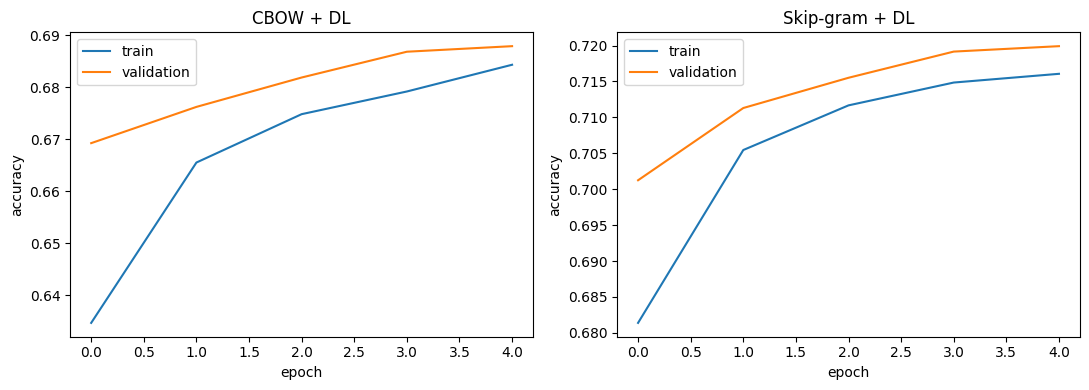

In [ ]:
# Training curves
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, h, t in zip(ax, [hist_cbow, hist_sg], ["CBOW + DL", "Skip-gram + DL"]):
    a.plot(h.history["accuracy"], label="train")
    a.plot(h.history["val_accuracy"], label="validation")
    a.set_title(t); a.set_xlabel("epoch"); a.set_ylabel("accuracy"); a.legend()
plt.tight_layout(); plt.show()

## 6. Model Evaluation

,Accuracy,Precision,Recall,F1-score
Bernoulli Naive Bayes,0.771200,0.755900,0.800500,0.777600
Linear SVM,0.770400,0.762900,0.784100,0.773400
Logistic Regression,0.786200,0.777100,0.802100,0.789400
CBOW + Deep Learning,0.683700,0.740500,0.564900,0.640900
Skip-gram + Deep Learning,0.719700,0.729300,0.698000,0.713300



Best model (by F1-score): Logistic Regression
Accuracy = 0.7862 | F1 = 0.7894
Better embedding method (by F1-score): Skip-gram


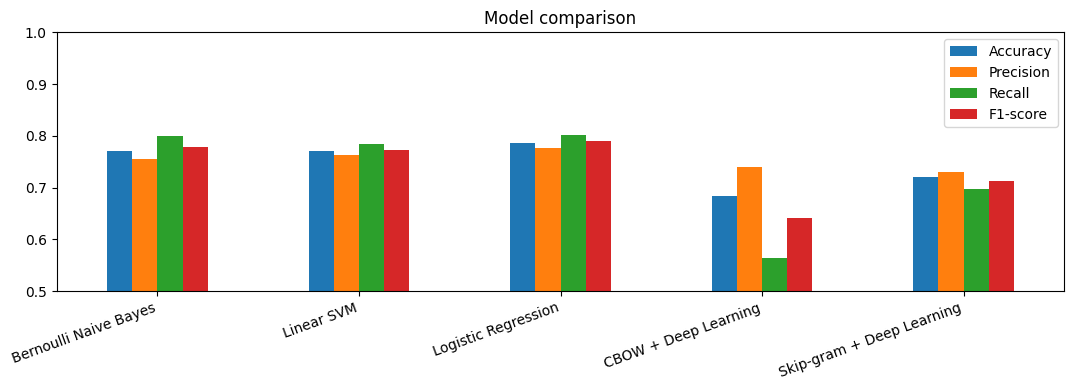

In [ ]:
# Comparison table of all five models
order = ["Bernoulli Naive Bayes", "Linear SVM", "Logistic Regression",
         "CBOW + Deep Learning", "Skip-gram + Deep Learning"]
comparison = pd.DataFrame(results).T.loc[order].round(4)
display(comparison.style.highlight_max(axis=0, color="lightgreen"))

best_model = comparison["F1-score"].idxmax()
print(f"\nBest model (by F1-score): {best_model}")
print(f"Accuracy = {comparison.loc[best_model, 'Accuracy']:.4f} | F1 = {comparison.loc[best_model, 'F1-score']:.4f}")

better_emb = ("CBOW" if comparison.loc["CBOW + Deep Learning", "F1-score"] >=
              comparison.loc["Skip-gram + Deep Learning", "F1-score"] else "Skip-gram")
print(f"Better embedding method (by F1-score): {better_emb}")

comparison.plot(kind="bar", figsize=(11, 4), ylim=(0.5, 1))
plt.title("Model comparison"); plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

## 7. Sample Predictions

In [ ]:
samples = ["I love this!", "I hate that!", "It was okay, not great."]

def label(p):
    return "Positive" if p == 1 else "Negative"

rows = []
for s in samples:
    c = clean_text(s)
    v = tfidf.transform([c])
    seq = pad([to_ids(c)])
    rows.append({
        "Tweet": s,
        "Bernoulli NB": label(bnb.predict(v)[0]),
        "Linear SVM": label(svm.predict(v)[0]),
        "Logistic Regression": label(lr.predict(v)[0]),
        "CBOW + DL": label(int(dl_cbow.predict(seq, verbose=0)[0][0] > 0.5)),
        "Skip-gram + DL": label(int(dl_sg.predict(seq, verbose=0)[0][0] > 0.5)),
    })
pd.DataFrame(rows).set_index("Tweet")

,Bernoulli NB,Linear SVM,Logistic Regression,CBOW + DL,Skip-gram + DL
Tweet,,,,,
I love this!,Positive,Positive,Positive,Positive,Positive
I hate that!,Negative,Negative,Negative,Negative,Negative
"It was okay, not great.",Positive,Positive,Positive,Negative,Positive


## 8. Discussion

**CBOW vs Skip-gram.** CBOW takes the surrounding context words and predicts the center word, while Skip-gram takes the center word and predicts each of its context words. CBOW averages the context, so it trains faster and works well for frequent words. Skip-gram makes a separate prediction for every context word, so it is slower but usually learns better vectors for rare words and small datasets.

**Which embedding method performed better?** Skip-gram performed better. Skip-gram + Deep Learning reached 0.7197 accuracy and 0.7133 F1-score, compared with 0.6837 accuracy and 0.6409 F1-score for CBOW + Deep Learning. CBOW's weaker result comes mainly from its low recall on positive tweets (0.5649 vs 0.6980 for Skip-gram), meaning it labeled many positive tweets as negative. The nearest-word check for "love" supports this: Skip-gram returned close variants of the word (loves, iloveyou, loveeee), while CBOW returned words that merely appear around it (music, hey, song). Skip-gram makes one prediction per context word, so it received far more training pairs (about 1.7M vs 0.6M) from the same tweets, which gives better vectors when data and epochs are limited.

**Which model achieved the best results?** Logistic Regression with TF-IDF achieved the best results on every metric (accuracy 0.7862, precision 0.7771, recall 0.8021, F1-score 0.7894), followed by Bernoulli Naive Bayes (0.7712) and Linear SVM (0.7704). Both deep learning models were behind the traditional models (0.7197 for Skip-gram and 0.6837 for CBOW). On Sentiment140, TF-IDF models are usually among the strongest because they see every word and bigram directly and are easy to train.

**Why models produce different results.**
1. Text representation: TF-IDF keeps every word and its importance (bigrams add some context), while embeddings compress each word into 50 numbers and average pooling discards word order.
2. Embedding quality: the embeddings were trained from scratch on a limited sample for few epochs, so more data and epochs would improve them.
3. Model assumptions: Bernoulli Naive Bayes assumes independent words and only uses word presence/absence, SVM and Logistic Regression learn a linear decision boundary, and the neural network can learn non-linear patterns but its input (frozen embeddings) is limited.
4. Data quality: tweets are short, noisy, and often sarcastic, and the labels were generated automatically, so accuracy is capped at roughly 80%.
5. Hard sentences such as "It was okay, not great." are ambiguous, so different models can disagree on them.
In the sample predictions, "It was okay, not great." was labeled Positive by Bernoulli NB, Linear SVM, Logistic Regression and Skip-gram + DL, and Negative only by CBOW + DL, whose bias toward the negative class (positive recall 0.56) makes that answer partly luck.